# VulnLab — the NumPy training loop

Steps 2 and 3 of the build plan. Logistic regression trained by gradient descent, written by
hand in NumPy so every iteration can be paused and looked at. Then a check against
scikit-learn on the same data.

**Before running:** build the dataset once from the repo root with `python3 build_dataset.py`.
Then run this notebook top to bottom.

| Part | What it does | Done when |
|---|---|---|
| 1 | The loop, as a generator | - |
| 2 | Toy data test | Loss falls and the two clouds separate |
| 3 | Real data | Loss falls on the vulnerability CSV |
| 4 | Metrics + confusion matrix | Numbers printed |
| 5 | scikit-learn check | Both models agree within tolerance |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# Works whether the notebook runs from notebooks/ or from the repo root.
DATA = next(p for p in [Path("../data"), Path("data")] if p.exists())

## Part 1 — The loop

One iteration is four lines. These match steps 3 to 6 of Figure 2 in the SDD.

```
1  p    = sigmoid(Xw + b)          # predict
2  loss = log loss(p, y)           # measure error
3  d    = X'(p - y) / n            # compute gradient
4  w    = w - lr * d               # update weights (and b = b - lr * mean(p - y))
```

`gradient_descent` is a **generator**. It pauses after every line and hands back the current
state, including `active_line`, so the Step button can later highlight the line that just ran.
`train()` drains it and keeps only the state at the end of each iteration.

In [2]:
PSEUDO_CODE = [
    "p    = sigmoid(Xw + b)",
    "loss = log loss(p, y)",
    "d    = X'(p - y) / n",
    "w    = w - lr * d",
]


def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))   # clip so exp() can't overflow


def log_loss(p, y):
    p = np.clip(p, 1e-12, 1 - 1e-12)                   # log(0) is -infinity
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


def gradient_descent(X, y, lr, n_iters):
    n, d = X.shape
    w = np.zeros(d)
    b = 0.0
    for step in range(1, n_iters + 1):
        p = sigmoid(X @ w + b)
        yield {"step": step, "weights": w.copy(), "bias": b, "loss": None, "active_line": 1}

        loss = log_loss(p, y)
        yield {"step": step, "weights": w.copy(), "bias": b, "loss": loss, "active_line": 2}

        error = p - y
        grad_w = X.T @ error / n
        grad_b = error.mean()
        yield {"step": step, "weights": w.copy(), "bias": b, "loss": loss, "active_line": 3}

        w = w - lr * grad_w
        b = b - lr * grad_b
        yield {"step": step, "weights": w.copy(), "bias": b, "loss": loss, "active_line": 4}


def train(X, y, lr, n_iters):
    """Run every iteration. Returns one record per iteration (the state after line 4)."""
    return [s for s in gradient_descent(X, y, lr, n_iters) if s["active_line"] == 4]


def predict_proba(X, weights, bias):
    return sigmoid(X @ weights + bias)


def apply_threshold(probs, t=0.5):
    return (probs >= t).astype(int)

## Part 2 — Toy data first

Two clouds of points: one labeled 0, one labeled 1. If the loop can't separate these, the bug
is in the loop. If it works here but not on the real data, the problem is the data.

loss: 0.6931 -> 0.0196
accuracy on toy data: 99.5%


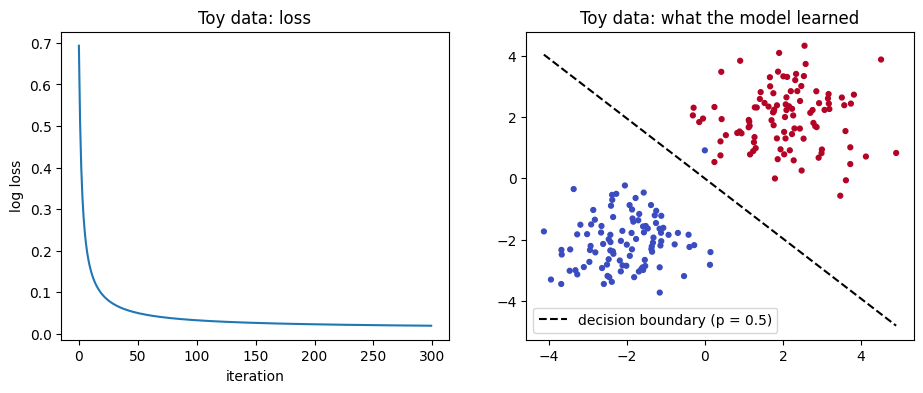

In [3]:
n_toy = 200
X_toy = np.vstack([rng.normal([-2, -2], 1.0, size=(n_toy // 2, 2)),
                   rng.normal([2, 2], 1.0, size=(n_toy // 2, 2))])
y_toy = np.array([0] * (n_toy // 2) + [1] * (n_toy // 2))

toy_hist = train(X_toy, y_toy, lr=0.1, n_iters=300)
toy_last = toy_hist[-1]
toy_acc = (apply_threshold(predict_proba(X_toy, toy_last["weights"], toy_last["bias"])) == y_toy).mean()

print(f"loss: {toy_hist[0]['loss']:.4f} -> {toy_last['loss']:.4f}")
print(f"accuracy on toy data: {toy_acc:.1%}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot([s["loss"] for s in toy_hist])
ax1.set(title="Toy data: loss", xlabel="iteration", ylabel="log loss")

ax2.scatter(X_toy[:, 0], X_toy[:, 1], c=y_toy, cmap="coolwarm", s=12)
w1, w2 = toy_last["weights"]
xs = np.linspace(X_toy[:, 0].min(), X_toy[:, 0].max(), 50)
ax2.plot(xs, -(w1 * xs + toy_last["bias"]) / w2, "k--", label="decision boundary (p = 0.5)")
ax2.set(title="Toy data: what the model learned")
ax2.legend()
plt.show()

assert toy_last["loss"] < toy_hist[0]["loss"], "loss did not go down - check the loop"

### Stepping by hand

This is what the Step button (build step 5) will do. Run the next cell over and over
(Ctrl+Enter keeps you on it). Each run executes **one line** of the loop. Watch the arrow move
and the numbers change. Re-run the cell above it to start over.

In [4]:
stepper = gradient_descent(X_toy, y_toy, lr=0.1, n_iters=5)

In [5]:
state = next(stepper, None)
if state is None:
    print("Iteration limit reached. Re-run the cell above to start over.")
else:
    print(f"iteration {state['step']}")
    for i, line in enumerate(PSEUDO_CODE, start=1):
        print(f"{'->' if i == state['active_line'] else '  '} {i}  {line}")
    loss = "not computed yet" if state["loss"] is None else f"{state['loss']:.4f}"
    print(f"\nweights = {np.round(state['weights'], 4)}   bias = {state['bias']:.4f}   loss = {loss}")

iteration 1
-> 1  p    = sigmoid(Xw + b)
   2  loss = log loss(p, y)
   3  d    = X'(p - y) / n
   4  w    = w - lr * d

weights = [0. 0.]   bias = 0.0000   loss = not computed yet


## Part 3 — Real data

Load the CSV from build step 1 and pick the features.

**Leakage:** the label is built from `kev_listed`, `epss_score`, and `internet_facing` (see
`data/schema.md`). `kev_listed` is left out of the features by default. If the model could see
it, it would copy it instead of learning. It stays in the CSV for the KEV readout later.
Change `FEATURES` to experiment.

In [6]:
df = pd.read_csv(DATA / "vulnlab_prioritization.csv")

FEATURES = ["cvss_base", "cvss_av_network", "cvss_ac_low", "cvss_pr_none", "cvss_ui_none",
            "epss_score", "asset_criticality", "days_open", "internet_facing"]

X = df[FEATURES].to_numpy(dtype=float)
y = df["label"].to_numpy()

print(f"{len(df):,} rows | {y.sum():,} FIX NOW | {(1 - y).sum():,} DEFER")
df.head()

10,000 rows | 2,264 FIX NOW | 7,736 DEFER


,cve_id,cvss_base,cvss_av_network,cvss_ac_low,cvss_pr_none,cvss_ui_none,epss_score,kev_listed,asset_criticality,days_open,internet_facing,label
0,CVE-2018-0001,9.8,1,1,1,1,0.06335,0,1,205,0,0
1,CVE-2018-0125,9.8,1,1,1,1,0.55186,1,2,339,0,1
2,CVE-2018-0137,8.6,1,1,1,1,0.01589,0,4,204,1,1
3,CVE-2018-0147,9.8,1,1,1,1,0.18212,1,5,125,1,1
4,CVE-2018-0151,9.8,1,1,1,1,0.14197,1,1,337,1,1


**Split, then scale.** 80% to train, 20% held back to test, with the same FIX NOW share in
both. Scaling puts every feature around 0 so a 0–365 column like `days_open` doesn't drown out
a 0–1 column like `epss_score`. The mean and spread come from the **training rows only**, so
the test rows stay unseen.

In [7]:
from sklearn.model_selection import train_test_split

X_train_raw, X_test_raw, y_train, y_test, kev_train, kev_test = train_test_split(
    X, y, df["kev_listed"].to_numpy(), test_size=0.2, random_state=SEED, stratify=y)

mu = X_train_raw.mean(axis=0)
sd = X_train_raw.std(axis=0)
X_train = (X_train_raw - mu) / sd
X_test = (X_test_raw - mu) / sd

print(f"train: {len(y_train):,} rows   test: {len(y_test):,} rows")

train: 8,000 rows   test: 2,000 rows


loss: 0.6931 -> 0.3192


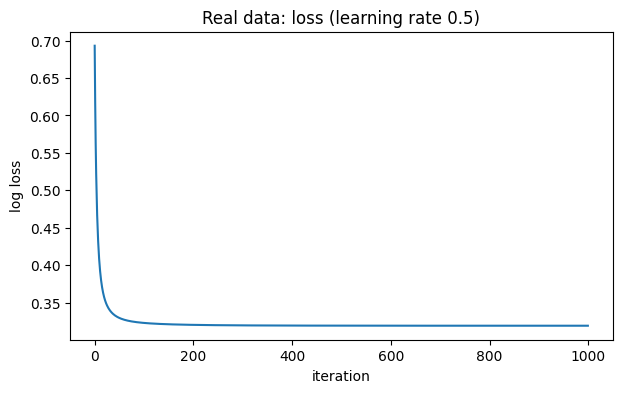

,weight
epss_score,2.586237
internet_facing,1.013535
cvss_base,0.623059
asset_criticality,0.096892
cvss_pr_none,0.039486
days_open,-0.032554
cvss_ui_none,-0.035213
cvss_ac_low,-0.056076
cvss_av_network,-0.089437


In [8]:
LR = 0.5
N_ITERS = 1000

hist = train(X_train, y_train, LR, N_ITERS)
last = hist[-1]

print(f"loss: {hist[0]['loss']:.4f} -> {last['loss']:.4f}")
plt.figure(figsize=(7, 4))
plt.plot([s["loss"] for s in hist])
plt.title(f"Real data: loss (learning rate {LR})")
plt.xlabel("iteration")
plt.ylabel("log loss")
plt.show()

pd.DataFrame({"weight": last["weights"]}, index=FEATURES).sort_values("weight", ascending=False)

**Reading the weights:** positive pushes toward FIX NOW, negative toward DEFER, near 0 means
the model learned to ignore it. `asset_criticality` and `days_open` are random and play no part
in the label rule, so their weights should end up close to 0.

### Learning rate

The same loop with three step sizes. Too small crawls. About right drops fast, then flattens.

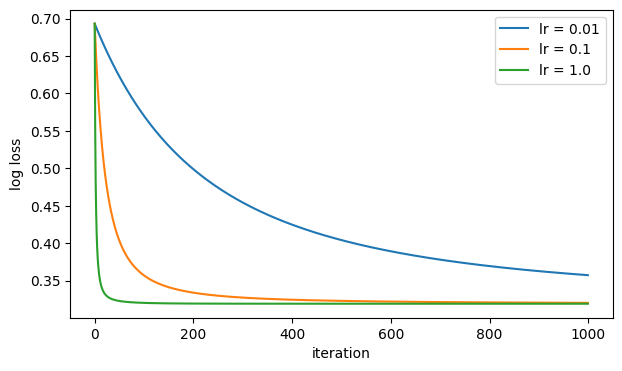

In [9]:
plt.figure(figsize=(7, 4))
for lr in [0.01, 0.1, 1.0]:
    plt.plot([s["loss"] for s in train(X_train, y_train, lr, N_ITERS)], label=f"lr = {lr}")
plt.xlabel("iteration")
plt.ylabel("log loss")
plt.legend()
plt.show()

## Part 4 — How good is it?

Scored on the 20% test rows the model never trained on. Threshold 0.5: FIX NOW if p ≥ 0.5.

In [10]:
THRESHOLD = 0.5


def score(y_true, y_pred):
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"accuracy": (tp + tn) / len(y_true), "precision": precision, "recall": recall,
            "f1": f1, "tp": tp, "fp": fp, "fn": fn, "tn": tn}


probs = predict_proba(X_test, last["weights"], last["bias"])
y_pred = apply_threshold(probs, THRESHOLD)
mine = score(y_test, y_pred)

print(pd.DataFrame(
    [[mine["tp"], mine["fp"]], [mine["fn"], mine["tn"]]],
    index=["predicted FIX NOW", "predicted DEFER"],
    columns=["actually FIX NOW", "actually DEFER"]))
print()
print({k: round(mine[k], 4) for k in ["accuracy", "precision", "recall", "f1"]})
print(f"\nAlways saying DEFER would score {(y_test == 0).mean():.1%} accuracy and catch nothing.")

                   actually FIX NOW  actually DEFER
predicted FIX NOW               220              15
predicted DEFER                 233            1532

{'accuracy': 0.876, 'precision': 0.9362, 'recall': 0.4857, 'f1': 0.6395}

Always saying DEFER would score 77.3% accuracy and catch nothing.


**KEV readout (preview of R23).** `kev_listed` wasn't a feature, so this is a fair check.

In [11]:
deferred = y_pred == 0
print(f"The model deferred {deferred.sum():,} test rows. "
      f"{int(kev_test[deferred].sum())} of them are in the KEV catalog.")

The model deferred 1,765 test rows. 91 of them are in the KEV catalog.


## Part 5 — Check against scikit-learn

Same rows, same scaling, same threshold. scikit-learn adds a penalty (regularization) by
default and the hand-written loop doesn't, so it's turned off with `C=np.inf` (an infinitely weak
penalty; older scikit-learn versions spell this `penalty=None`).
Expect close, not identical.

In [12]:
import warnings
from sklearn.linear_model import LogisticRegression

# scikit-learn 1.8 notes that C=inf means "no penalty". That's the point, so hide the notice.
warnings.filterwarnings("ignore", message="Setting penalty=None")

TOLERANCE = 0.01   # metrics may differ by at most this much

sk = LogisticRegression(C=np.inf, max_iter=5000).fit(X_train, y_train)
theirs = score(y_test, apply_threshold(sk.predict_proba(X_test)[:, 1], THRESHOLD))

metrics = ["accuracy", "precision", "recall", "f1"]
compare = pd.DataFrame({"NumPy loop": [mine[m] for m in metrics],
                        "scikit-learn": [theirs[m] for m in metrics]}, index=metrics)
compare["difference"] = (compare["NumPy loop"] - compare["scikit-learn"]).abs()
print(compare.round(4))

agree = (compare["difference"] <= TOLERANCE).all()
print(f"\nAgree within {TOLERANCE}: {'YES' if agree else 'NO'}")

           NumPy loop  scikit-learn  difference
accuracy       0.8760        0.8760         0.0
precision      0.9362        0.9362         0.0
recall         0.4857        0.4857         0.0
f1             0.6395        0.6395         0.0

Agree within 0.01: YES


In [13]:
pd.DataFrame({"NumPy loop": np.append(last["weights"], last["bias"]),
              "scikit-learn": np.append(sk.coef_[0], sk.intercept_[0])},
             index=FEATURES + ["bias"]).round(3)

,NumPy loop,scikit-learn
cvss_base,0.623,0.622
cvss_av_network,-0.089,-0.090
cvss_ac_low,-0.056,-0.056
cvss_pr_none,0.039,0.040
cvss_ui_none,-0.035,-0.035
epss_score,2.586,2.615
asset_criticality,0.097,0.097
days_open,-0.033,-0.033
internet_facing,1.014,1.015
bias,-1.400,-1.394


If the weights differ a little but the metrics agree, the loop just hasn't fully converged in
1,000 iterations. scikit-learn keeps going until it does. Raise `N_ITERS` in Part 3 and the
weights move closer.